# 01 - Data Understanding

## 1. Project Objective

This notebook is the first step of our Mobile Money fraud detection project. We use PaySim, a synthetic dataset of Mobile Money transactions ([Kaggle link](https://www.kaggle.com/datasets/ealaxi/paysim1)).

PaySim is **not real banking data**. It was made with a simulator that uses statistics from real mobile money logs. We need to keep this in mind for every conclusion in this project.

Before building any model, we want to understand the data. How big is it? What does each column mean? How rare is fraud? Do some columns look risky for data leakage? We do no feature engineering and no modeling in this notebook. We only want to understand the data.

## 2. Dataset Loading

The file has about 6.3 million rows. To keep memory usage reasonable we set
explicit dtypes instead of letting pandas infer them (inference forces pandas
to read the file more than once and often picks `int64`/`float64` when smaller
types would work fine).

In [26]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [27]:
DATA_PATH = os.path.join('..', 'data', 'raw', 'PS_20174392719_1491204439457_log.csv')

# Explicit dtypes to reduce memory footprint on a 6.3M row file.
# 'type' is a category with only 5 possible values.
# isFraud / isFlaggedFraud are 0/1 flags, int8 is enough.
dtypes = {
    'step': 'int32',
    'type': 'category',
    'amount': 'float64',
    'nameOrig': 'string',
    'oldbalanceOrg': 'float64',
    'newbalanceOrig': 'float64',
    'nameDest': 'string',
    'oldbalanceDest': 'float64',
    'newbalanceDest': 'float64',
    'isFraud': 'int8',
    'isFlaggedFraud': 'int8',
}

start = time.time()
df = pd.read_csv(DATA_PATH, dtype=dtypes)
load_time = time.time() - start

print(f'Loaded in {load_time:.1f} seconds')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB')

Loaded in 7.8 seconds
Memory usage: 534.2 MB


## 3. Dataset Dimensions

In [28]:
n_rows, n_cols = df.shape
print(f'Rows: {n_rows:,}')
print(f'Columns: {n_cols}')

Rows: 6,362,620
Columns: 11


## 4. Column Overview

What each column represents, based on the PaySim documentation:

| Column | Meaning |
|---|---|
| `step` | Time unit. 1 step = 1 hour of simulated time. |
| `type` | Transaction type: CASH-IN, CASH-OUT, DEBIT, PAYMENT, TRANSFER. |
| `amount` | Transaction amount, in local currency. |
| `nameOrig` | ID of the account that starts the transaction. |
| `oldbalanceOrg` | Balance of the origin account before the transaction. |
| `newbalanceOrig` | Balance of the origin account after the transaction. |
| `nameDest` | ID of the account that receives the transaction. |
| `oldbalanceDest` | Balance of the destination account before the transaction. |
| `newbalanceDest` | Balance of the destination account after the transaction. |
| `isFraud` | Target. 1 if the transaction is fraudulent. |
| `isFlaggedFraud` | Flag set by PaySim's own rule-based system for illegal attempts to transfer more than 200,000 in a single transaction. |

`isFlaggedFraud` is not something we should engineer or trust - it is PaySim's
own simulated control, not ground truth. We keep it for now but it needs to be
looked at separately from `isFraud`.

In [29]:
df.columns.tolist()

['step',
 'type',
 'amount',
 'nameOrig',
 'oldbalanceOrg',
 'newbalanceOrig',
 'nameDest',
 'oldbalanceDest',
 'newbalanceDest',
 'isFraud',
 'isFlaggedFraud']

## 5. Data Types

In [30]:
df.dtypes

step                 int32
type              category
amount             float64
nameOrig            string
oldbalanceOrg      float64
newbalanceOrig     float64
nameDest            string
oldbalanceDest     float64
newbalanceDest     float64
isFraud               int8
isFlaggedFraud        int8
dtype: object

In [31]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            int32   
 1   type            category
 2   amount          float64 
 3   nameOrig        string  
 4   oldbalanceOrg   float64 
 5   newbalanceOrig  float64 
 6   nameDest        string  
 7   oldbalanceDest  float64 
 8   newbalanceDest  float64 
 9   isFraud         int8    
 10  isFlaggedFraud  int8    
dtypes: category(1), float64(5), int32(1), int8(2), string(2)
memory usage: 509.5 MB


## 6. First Rows

In [32]:
df.head(10)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0
5,1,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0
6,1,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0
7,1,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0
8,1,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0
9,1,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0


## 7. Descriptive Statistics

In [33]:
numeric_cols = ['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
df[numeric_cols].describe()

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06
std,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05
75%,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06
max,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08


In [34]:
df['type'].describe()

count      6362620
unique           5
top       CASH_OUT
freq       2237500
Name: type, dtype: object

## 8. Missing Values

In [35]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(3)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct})

,missing_count,missing_pct
step,0,0.0
type,0,0.0
amount,0,0.0
nameOrig,0,0.0
oldbalanceOrg,0,0.0
newbalanceOrig,0,0.0
nameDest,0,0.0
oldbalanceDest,0,0.0
newbalanceDest,0,0.0
isFraud,0,0.0


## 9. Duplicate Rows

Checking exact duplicate rows on 6.3M rows is expensive but doable in one pass.
We also check duplicated `nameOrig` + `step` + `amount` combinations, which is
a softer notion of duplicate (same account doing the exact same thing in the
same hour).

In [36]:
n_exact_duplicates = df.duplicated().sum()
print(f'Exact duplicate rows: {n_exact_duplicates:,}')

Exact duplicate rows: 0


## 10. Categorical Variables

`type` has a small, fixed number of categories. `nameOrig` and `nameDest` are
essentially IDs, so what matters for them is cardinality, not the values
themselves.

In [37]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [38]:
print(f"Unique nameOrig: {df['nameOrig'].nunique():,}")
print(f"Unique nameDest: {df['nameDest'].nunique():,}")
print(f"Rows: {len(df):,}")

Unique nameOrig: 6,353,307
Unique nameDest: 2,722,362
Rows: 6,362,620


## 11. Target Variable Analysis

This is the key number for the whole project: how rare is fraud, exactly?
This drives every later decision about metrics, resampling and thresholds.

In [39]:
fraud_counts = df['isFraud'].value_counts()
fraud_pct = df['isFraud'].value_counts(normalize=True) * 100

print('Legit (0) vs Fraud (1):')
print(fraud_counts)
print()
print('Percentage:')
print(fraud_pct.round(4))

n_fraud = fraud_counts.get(1, 0)
n_legit = fraud_counts.get(0, 0)
ratio = n_legit / n_fraud if n_fraud > 0 else float('nan')
print(f'\nFor every fraud case, there are about {ratio:.0f} legit transactions.')

Legit (0) vs Fraud (1):
isFraud
0    6354407
1       8213
Name: count, dtype: int64

Percentage:
isFraud
0    99.8709
1     0.1291
Name: proportion, dtype: float64

For every fraud case, there are about 774 legit transactions.


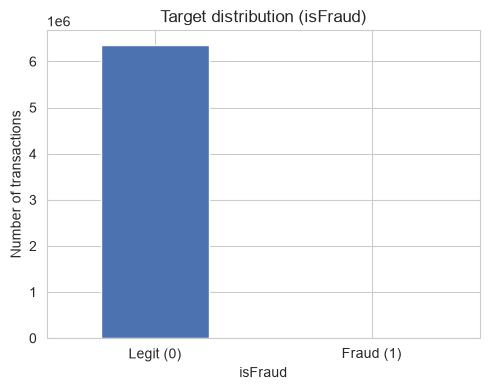

In [40]:
fig, ax = plt.subplots(figsize=(5, 4))
fraud_counts.plot(kind='bar', ax=ax, color=['#4C72B0', '#C44E52'])
ax.set_xticklabels(['Legit (0)', 'Fraud (1)'], rotation=0)
ax.set_ylabel('Number of transactions')
ax.set_title('Target distribution (isFraud)')
plt.tight_layout()
plt.savefig('../reports/figures/target_distribution.png', dpi=120)
plt.show()

In [41]:
# isFlaggedFraud is PaySim's own detection rule, separate from the ground truth isFraud.
# Checking how much overlap there is between the two.
pd.crosstab(df['isFraud'], df['isFlaggedFraud'], margins=True)

isFlaggedFraud,0,1,All
isFraud,,,
0,6354407,0,6354407
1,8197,16,8213
All,6362604,16,6362620


`isFlaggedFraud` fires only 16 times in total, and all 16 are real fraud
(no false positives), but that is 16 out of 8,213 - 0.19% recall. PaySim's
built-in rule barely catches anything.

## 12. Transaction Type Analysis

Question: is fraud spread across all transaction types, or concentrated in
a few of them?

In [42]:
type_fraud = pd.crosstab(df['type'], df['isFraud'])
type_fraud.columns = ['legit', 'fraud']
type_fraud['fraud_rate_pct'] = (type_fraud['fraud'] / (type_fraud['legit'] + type_fraud['fraud']) * 100).round(4)
type_fraud.sort_values('fraud', ascending=False)

,legit,fraud,fraud_rate_pct
type,,,
CASH_OUT,2233384,4116,0.1840
TRANSFER,528812,4097,0.7688
CASH_IN,1399284,0,0.0000
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000


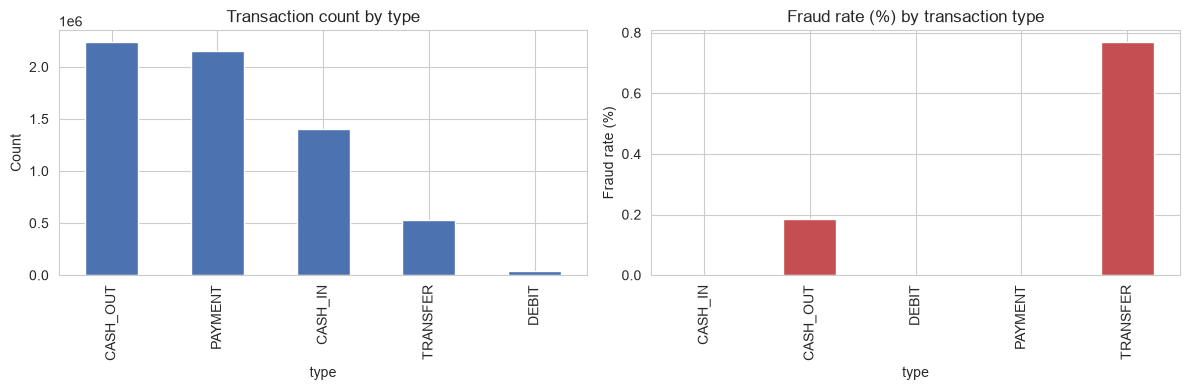

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['type'].value_counts().plot(kind='bar', ax=axes[0], color='#4C72B0')
axes[0].set_title('Transaction count by type')
axes[0].set_ylabel('Count')

type_fraud['fraud_rate_pct'].plot(kind='bar', ax=axes[1], color='#C44E52')
axes[1].set_title('Fraud rate (%) by transaction type')
axes[1].set_ylabel('Fraud rate (%)')

plt.tight_layout()
plt.savefig('../reports/figures/fraud_rate_by_type.png', dpi=120)
plt.show()

Fraud is entirely concentrated in `CASH_OUT` and `TRANSFER`. `PAYMENT` is
the most common type by volume but has zero fraud, which lines up with
`PAYMENT` being the only type that goes to merchant accounts (checked later
in the leakage section).

## 13. Transaction Amount Analysis

Question: are fraudulent transactions bigger than legit ones? We look at
basic statistics per class, then at the distribution on a log scale (raw
`amount` is extremely skewed, a normal histogram would be unreadable).

In [44]:
df.groupby('isFraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


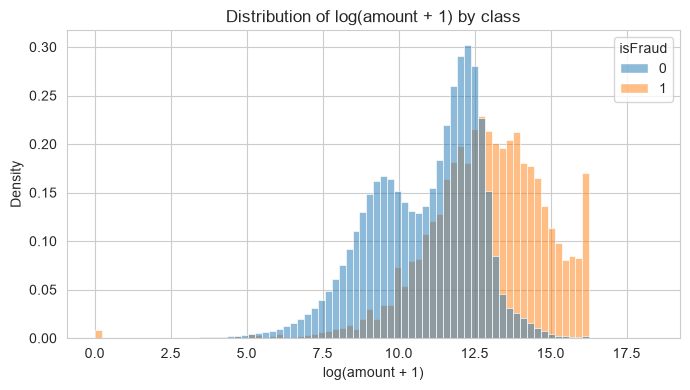

In [45]:
# log1p handles the amount=0 rows without producing -inf.
df['amount_log'] = np.log1p(df['amount'])

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x='amount_log', hue='isFraud', bins=80, stat='density',
             common_norm=False, ax=ax)
ax.set_title('Distribution of log(amount + 1) by class')
ax.set_xlabel('log(amount + 1)')
plt.tight_layout()
plt.savefig('../reports/figures/amount_log_distribution.png', dpi=120)
plt.show()

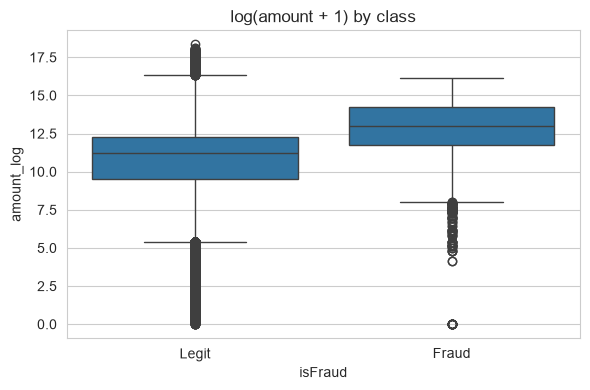

In [46]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='isFraud', y='amount_log', ax=ax)
ax.set_xticklabels(['Legit', 'Fraud'])
ax.set_title('log(amount + 1) by class')
plt.tight_layout()
plt.savefig('../reports/figures/amount_boxplot.png', dpi=120)
plt.show()

Fraud amounts skew higher, but the two distributions overlap substantially.
Amount by itself is a useful signal, not a shortcut to perfect separation -
unlike what we are about to see with the balance columns below.

## 14. Initial Observations

- **Fraud rate**: 8,213 fraud out of 6,362,620 transactions, 0.129%. About 774
  legit transactions for every fraud case. Confirms accuracy is useless here;
  PR-AUC and recall/precision will drive model choice.
- **Transaction type**: fraud only happens in `CASH_OUT` (0.184% fraud rate)
  and `TRANSFER` (0.769%). `CASH_IN`, `DEBIT`, `PAYMENT` have zero fraud
  cases across 3.59M transactions combined. `type` is going to be one of the
  strongest predictors by itself.
- **Amount**: fraud has a much higher median amount than legit (441,423 vs
  74,685, about 6x), but the log-amount histogram shows the two
  distributions still overlap a lot, so amount alone won't separate the
  classes cleanly.
- **Data quality**: no missing values, no exact duplicates.
- **Unexpected finding**: PaySim's own `isFlaggedFraud` rule only catches 16
  of the 8,213 real fraud cases (0.19% recall). It is not usable as a
  feature - see the decision below.

> **Decision**: exclude `isFlaggedFraud` from the model features.
> **Reason**: 0.19% recall against the real target, it is a threshold rule
> on `amount` that catches almost nothing. Keeping it risks giving a false
> impression of a strong signal.

## 15. Potential Data Leakage

The columns `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest`, and `newbalanceDest` need special attention. PaySim's own documentation says that destination account balances are not tracked correctly for fraudulent `CASH-OUT` and `TRANSFER` transactions. They can be left at 0 or stay unchanged. This happens because of how the simulator creates fraud.

This means that if these columns look very different for fraud and non-fraud, it may not be because fraudsters really have unusual balances. It may just be a side effect of how PaySim generated the fraud rows.

We check this here, but we do **not** decide yet whether to drop these columns. That decision needs a separate leakage analysis, where we compare a model trained with these columns to a model trained without them.

In [47]:
balance_cols = ['oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
df.groupby('isFraud')[balance_cols].describe().T

isFraud                          0             1
oldbalanceOrg  count  6.354407e+06  8.213000e+03
               mean   8.328287e+05  1.649668e+06
               std    2.887144e+06  3.547719e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  1.258224e+05
               50%    1.406900e+04  4.389835e+05
               75%    1.069695e+05  1.517771e+06
               max    4.381886e+07  5.958504e+07
newbalanceOrig count  6.354407e+06  8.213000e+03
               mean   8.559702e+05  1.923926e+05
               std    2.924987e+06  1.965666e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    0.000000e+00  0.000000e+00
               75%    1.447307e+05  0.000000e+00
               max    4.368662e+07  4.958504e+07
oldbalanceDest count  6.354407e+06  8.213000e+03
               mean   1.101421e+06  5.442496e+05
               std    3.399202e+06  3.336421e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    1.333118e+05  0.000000e+00
               75%    9.441446e+05  1.478287e+05
               max    3.560159e+08  2.362305e+08
newbalanceDest count  6.354407e+06  8.213000e+03
               mean   1.224926e+06  1.279708e+06
               std    3.673816e+06  3.908817e+06
               min    0.000000e+00  0.000000e+00
               25%    0.000000e+00  0.000000e+00
               50%    2.148817e+05  4.676420e+03
               75%    1.111975e+06  1.058725e+06
               max    3.561793e+08  2.367265e+08

In [48]:
# A simple consistency check: for a normal transaction,
# newbalanceOrig should be close to oldbalanceOrg - amount.
# We measure how often this holds, separately for fraud and legit rows.
expected_new_balance = df['oldbalanceOrg'] - df['amount']
balance_diff = (df['newbalanceOrig'] - expected_new_balance).abs()
df['balance_orig_consistent'] = balance_diff < 0.01

df.groupby('isFraud')['balance_orig_consistent'].mean().round(4)

isFraud
0    0.2009
1    0.9945
Name: balance_orig_consistent, dtype: float64

In [49]:
# Same check on the destination side: newbalanceDest vs oldbalanceDest + amount.
expected_new_dest = df['oldbalanceDest'] + df['amount']
dest_diff = (df['newbalanceDest'] - expected_new_dest).abs()
df['balance_dest_consistent'] = dest_diff < 0.01

df.groupby('isFraud')['balance_dest_consistent'].mean().round(4)

isFraud
0    0.3416
1    0.4350
Name: balance_dest_consistent, dtype: float64

In [50]:
# How often is the destination balance exactly zero (both before and after)?
# This is the pattern mentioned in PaySim's documentation for fraud cases.
zero_dest_balance = (df['oldbalanceDest'] == 0) & (df['newbalanceDest'] == 0)
df.groupby('isFraud').apply(lambda g: (zero_dest_balance.loc[g.index]).mean()).round(4)

isFraud
0    0.3640
1    0.4963
dtype: float64

## 16. Conclusion and Next Steps

This first look at the data shows a fraud pattern that is rare but clear in its structure:

- Fraud only happens in `CASH_OUT` and `TRANSFER` transactions.
- Fraudulent transactions usually involve larger amounts.
- The balance columns behave very differently between the two classes:
  - The origin balance formula holds in 20.1% of fraud cases, compared with 99.5% of non-fraud cases.
  - The destination balance stays at zero in 36.4% of one class, compared with 49.6% of the other.

However, these numbers come from all 5 transaction types. Fraud only occurs in 2 of them. So we can't yet tell if the gap is a real signal or just the result of comparing groups with different mixes of transaction types.

**Next notebook:** `02_data_quality.ipynb`. It will:

- Repeat the balance checks using only `CASH_OUT` and `TRANSFER` transactions, which removes the transaction-type problem.
- Look at patterns by `step`.
- Check zero-amount transactions.
- Check whether account IDs overlap.